# 实验课 04：一个小索引器怎样学会选择历史？

本课研究：**不改语言模型本身，只训练一个给历史位置打分的小模块，能否让它更接近完整注意力的读取分配？** 这个小模块叫索引器；本项目把这次“单层索引器可学习性验证”编号为 **G3a**。这里的编号只用于连接代码和记录，不是预备知识。

实际模型是 **Qwen3-0.6B**，约 6 亿参数。**主体冻结**表示原语言模型的参数全部保持不变，只更新第 14 层新增的索引参数。资料任务 **T1** 是“给一个编号，返回它对应的四位数值”。新生成的 64 份资料中，48 份组成**训练集**，用来更新参数；16 份组成**留出集**，不参与更新或选择训练轮数，只在最终参数固定后检查。每份约 2K，即约 2048 个 **token**（模型处理的文本单元，不等于字数）。

默认执行读取保存记录、画图，并运行一个 12 参数的小算例。CPU 是中央处理器；本课的小算例只在 CPU 计算，不下载或训练真实语言模型，也不启动 GPU（图形处理器）。它回答“选择更像完整注意力了吗”，本课没有测整模型答题准确率。

本课代码的 `torch` 是 PyTorch 张量计算库，张量就是多维数值数组；`MPS` 是它调用 Apple GPU 的后端。实际历史运行用主模型 bf16（每数 2 字节）和索引 fp32（每数 4 字节）；本页 CPU 算例不会启动那条 GPU 路径。

### 本课模型、选位与配置的含义

注意力用 **Q 查询向量**与各历史位置的 **K 键向量**计算匹配程度，再按权重组合 **V 内容向量**；保存历史 K/V 叫 KV 缓存。多个查询头（并行的注意力计算通道）共用同一组 K/V，叫一个 **KV 组**；实际模型本层有 8 组、每组 2 个查询头。

**Wq/Wk** 是本课新增的两个可训练矩阵，不是原模型生成 Q/K 的权重。它们把查询变成短向量 u、把历史键变成短向量 z，再由 u 与 z 的点积给历史位置打分。**r=32** 表示 u/z 各有 32 个坐标。**RoPE**是按原始位置旋转 Q/K、加入位置关系的计算；**P0** 是本项目的索引配置名：从主模型旋转前的 Q/K 生成 u/z，索引空间不再额外做一次位置旋转。它不表示输入完全没有位置信息。

**固定集合 F**是始终保留的首 4 与最近 64 个合法位置，重叠去重；合法指已计算且不是未来位置。F 之外是**候选域**，有 M 个位置。**ρ=1/8**用请求起始合法长度 N0 算 `k0=min(round(ρ×N0), 起始候选数)`，后续 k0 固定，本步实际 k 还受候选数限制；**top-k**取最高分的 k 个候选。总读取数是 |F|+k，不能直接说“只读八分之一”。

本课的对照代号：**C** 在候选中均匀随机选 k 个；**D0** 用未训练的初始索引参数选位；**D** 用训练后的参数选位；**R** 先付出完整注意力打分的成本，再按其权重取 top-k，作为昂贵的诊断参照。四者共享 F、候选和名额。R 不是免费加速方案，也不是答题质量上界。

**怎样读下面的来源记录。** 一次实际执行叫一次运行（`run`），`run_id` 是它的编号；`manifest` 是随运行保存的清单，记录数据、配置和源码来自哪里。文件的哈希（`hash` / `SHA-256` / `digest`）可理解为按文件内容算出的指纹，用来核对文件是否改变，不是成绩。`commit` / `revision` 是保存代码或模型的版本编号；`dirty diff` 是运行时尚未提交的修改记录，`None` 表示此项没有内容。`tokenizer` 是把文本拆成模型输入单元的分词器。`source_hashes` 列的是源码文件指纹；`HF_HUB_OFFLINE` 表示模型库是否处于离线模式。这里保留编号是为了追溯，不需要读者记住长字符串。

输出判定 `single_layer_descriptive_support` 表示“这批资料支持单层可学习性”，`insufficient_evidence` 表示证据不足；它们不是整模型通过/失败。`preflight` 是正式运行前的小批预检，`formal` 是正式运行，`done/incomplete` 分别表示完成/未完整完成。

In [1]:
from pathlib import Path
import importlib.util, hashlib, json, ast, sys
from IPython.display import display, Markdown, Code
ROOT = Path.cwd()
if not (ROOT / 'scripts/g3a_report.py').exists(): ROOT = ROOT.parent
spec = importlib.util.spec_from_file_location('g3a_report', ROOT / 'scripts/g3a_report.py')
report = importlib.util.module_from_spec(spec)
spec.loader.exec_module(report)
evidence = report.read_evidence()
summary = report.summarize(evidence)
display(Markdown(f"**判定：{summary['status']}**；正式运行 `{summary['run_id']}`；代码 `{summary['run_commit']}`。"))
print('数据、参数、逐题记录和源码归档哈希已核对。')

**判定：single_layer_descriptive_support**；正式运行 `g3a-20261018T122927Z-formal`；代码 `b998ee733b75af861613999fc3d4ec6c992b4835`。

数据、参数、逐题记录和源码归档哈希已核对。


## 1. 先看运行前预测，再看结果

预测在模型运行前提交。第一次预检遇到整句填充导致的长度振荡，未训练即停止；仅对 G3a 把约 2K 明确为 2048±64 token，保留原种子、样本数和目标位置规则。后续固定配置运行，未根据留出结果挑轮数或改模型。

在读下面保留的预测原文前，先认识其中三项指标：**教师**不是人工答案，而是完整注意力给各历史位置的权重；**KL**衡量索引概率分布与教师分布的差异，越小越接近；**条件覆盖率 coverage**衡量选中的候选保住了多少教师权重，越大越多；**局部输出误差**比较同一份 Q/K/V 下子集注意力与完整注意力的读出向量。它们的具体分母在第 3、4 节展开，不能互换成答题准确率。

“预检”只先用小批输入检查流程；“长度振荡”是生成器用整句填充时，资料长度在目标上下反复跳动。`2048±64` 明确允许的长度范围，不是事后挑掉难题。

In [2]:
task = (ROOT / 'docs/tasks/06_G3A_SINGLE_LAYER.md').read_text()
prediction = task.split('**运行前预测（原文保留）。**')[1].split('**正确性。**')[0]
display(Markdown('**原预测：**' + prediction))
print('预算累计秒数:', round(summary['budget']['used_seconds'], 2), '/ 7200')
print('各次运行:', [(r['run_id'], r['status']) for r in summary['budget']['runs']])

**原预测：** 预计训练 KL 下降；留出 KL 与 coverage 能否同步改善不确定。若留出平均 KL 低于 D0 与均匀分布，且同名额 coverage 高于 D0 与 C，记为本轮单层可学习性的描述性支持；局部输出误差独立报告，退化不得隐藏。没有达到这些方向也交付失败或证据不足，不调留出集重来，不宣称泛化保证或自动扩展。展示完整留出结果，并按最终查询的 coverage 差选最大改善/最差案例，明确它们不是随机典型样本。



预算累计秒数: 313.8 / 7200
各次运行: [('g3a-20261018T122458Z-preflight', 'incomplete'), ('g3a-20261018T122640Z-preflight', 'done'), ('g3a-20261018T122927Z-formal', 'done')]


## 2. 训练到底接在哪里？

完整模型先处理资料并保存历史状态，这叫 **Prefill**；然后把问题和聊天模板后缀逐 token 完整读取。聊天模板后缀是问题后要求助手开始回答的格式标记。这里保存下来的 Q/K/V 数组称为**冻结特征**：后续训练只使用这些固定数值，不让梯度（损失对参数的局部变化率）传回主模型。**反向图**是自动求导为回传梯度保留的计算依赖；分离特征（`detach`）切断这条连接。

只在第 14 层抽取问题/模板后缀中四个固定位置的查询，每个位置叫一条**查询行**，并保存它可合法读取的历史 K/V。其他层保持完整读取，不使用 D0 或 D。

实际形状的维度顺序是 Q `[组, 组内查询头, 查询行, 头维度]`，K/V `[组, 原始位置, 头维度]`。头维度是每个向量有几个数。`q_pre/k_pre` 指原模型归一化（调整尺度）之后、RoPE 之前的 Q/K；`q_main/k_main` 指 RoPE 之后的 Q/K；`query_positions` 是抽取查询的原位置，`prefix_len` 是资料前缀长度，形状 `[]` 表示单个数。索引用 pre 特征，教师和主读取用 main 特征，两者不能互换。

**优化器**是根据梯度修改参数的程序；下面核对它只持有新增的 Wq/Wk，同时核对主体参数没有变化。

本节的“梯度”指损失对参数的局部变化率，告诉优化器怎样微调参数可能减小损失；第 3a 节会展示具体数值。

**归一化**在这里是调整向量尺度；它与第 3 节把候选概率重新除以总和的“重新归一化”作用对象不同。

In [3]:
first = next(iter(evidence['manifest']['feature_files'].values()))
print('一份实际资料的形状:', json.dumps(first['shapes'], ensure_ascii=False, indent=2))
print('优化器仅持有:', evidence['manifest']['optimizer_parameters'])
print('可训练参数:', evidence['manifest']['trainable_parameters'])
print('主体前后哈希相同:', evidence['manifest']['body_hash_before'] == evidence['manifest']['body_hash_after_extraction'])

一份实际资料的形状: {
  "q_pre": [
    8,
    2,
    4,
    128
  ],
  "q_main": [
    8,
    2,
    4,
    128
  ],
  "k_pre": [
    8,
    2117,
    128
  ],
  "k_main": [
    8,
    2117,
    128
  ],
  "v": [
    8,
    2117,
    128
  ],
  "query_positions": [
    4
  ],
  "prefix_len": []
}
优化器仅持有: {'wq': [8, 32, 256], 'wk': [8, 32, 128]}
可训练参数: 98304
主体前后哈希相同: True


## 3. 教师分布不是答案标签

对每个查询头，完整注意力先计算查询与所有合法键的分数，再用 **softmax** 把分数变成非负、总和为 1 的权重；然后在共用一组 K/V 的查询头之间平均概率，得到本课的教师分布。不能先平均分数再 softmax，两种运算不同。

训练只要求索引器在候选域上选择。先去掉固定集合 F，记 **m_C（candidate_mass）**为候选位置在完整教师分布中原本占的总权重，再把各候选权重除以 m_C，使它们在候选域内总和为 1；这才是**条件分布**。例如候选原本只占全部权重的 20%，条件化后仍会被重新放大到 100%，所以必须同时保留 m_C。

设教师条件概率为 p、索引概率为 q，**KL 散度**为 (sum_j p_jlog(p_j/q_j))，衡量两份分布有多不同，越小越接近。这里 log 是自然对数，因此单位记作 **nats**。它是训练用的**损失 loss**，不是答案错几题。候选总权重小于 1e-4（0.0001）的查询/组不参与这项训练，保留跳过计数，不能填成“零误差”。

下面正式函数 `teacher` 构造教师与完整读出；`TrainableIndexer` 计算索引分数；其 `forward` 是从输入到分数的一次前向计算。**完整注意力“看哪里”，不等于正确答案“必须在哪里”。**

In [4]:
source = evidence['files']['source/src/attention_lab/g3a.py'].decode()
assert hashlib.sha256((ROOT / 'src/attention_lab/g3a.py').read_bytes()).hexdigest() == evidence['manifest']['sources']['src/attention_lab/g3a.py']
def show_source(name):
    node = next(node for node in ast.parse(source).body if getattr(node, 'name', None) == name)
    display(Code(ast.get_source_segment(source, node), language='python'))
show_source('teacher')
show_source('TrainableIndexer')

def teacher(q_main, k_main, v):
    """One query: [G,h,1,d], [G,N,d] -> per-head probabilities, group mean, full output.

    Average probabilities AFTER per-head softmax, never average logits first.
    Inputs already contain the main model's RoPE; only legal K/V are supplied.
    """
    q, k, value = (x.detach().float() for x in (q_main, k_main, v))
    logits = torch.matmul(q, k[:, None].transpose(-1, -2)) / math.sqrt(q.shape[-1])
    weights = logits.softmax(-1)
    return weights, weights.mean(1).squeeze(1), torch.matmul(weights, value[:, None])

class TrainableIndexer(torch.nn.Module):
    """The existing P0 formula, with exactly Wq/Wk trainable (no stale derived weights/z)."""

    def __init__(self, groups=8, heads_per_group=2, head_dim=128, r=32, seed=1803, device="cpu"):
        super().__init__()
        initial = GroupedIndexer(groups, heads_per_group, head_dim, r, seed=seed)
        self.r = r
        self.wq = torch.nn.Parameter(initial.wq.to(device))
        self.wk = torch.nn.Parameter(initial.wk.to(device))

    def forward(self, q_pre, k_pre):
        q = q_pre.detach().to(device=self.wq.device, dtype=self.wq.dtype)
        k = k_pre.detach().to(device=self.wk.device, dtype=self.wk.dtype)
        u = project_queries(q, (self.wq / math.sqrt(self.r)).transpose(1, 2))
        # z must be rebuilt after EVERY optimizer step; only body features are reusable.
        z = project_keys(k, self.wk)
        return torch.matmul(u, z)

    def save(self, path):
        np.savez_compressed(path, wq=self.wq.detach().cpu().numpy(), wk=self.wk.detach().cpu().numpy())

    def restore(self, path):
        with np.load(path, allow_pickle=False) as a, torch.no_grad():
            self.wq.copy_(torch.from_numpy(a["wq"]).to(self.wq.device))
            self.wk.copy_(torch.from_numpy(a["wk"]).to(self.wk.device))

索引器只更新 Wq/Wk。每次更新后，查询投影和索引 z 都重新计算；可复用的是冻结主体特征，不能复用旧参数投影出的 z。下面用同一 `.py` 的教师函数做 CPU 检查，不运行语言模型。

`kl_rows` 对各查询/组计算上述 KL；`gather_attention` 按名单取出原 K/V，再做主注意力。代码中的 `torch` 是 PyTorch 张量计算库，“张量”就是多维数值数组。下面两个头分别得到自己的概率，平均后仍须加总为 1。

In [5]:
sys.path.insert(0, str(ROOT / 'src'))
import torch
from attention_lab.g3a import teacher
q = torch.tensor([[[[1., 0.]], [[0., 1.]]]], device='cpu')
k = torch.tensor([[[1., 0.], [0., 1.], [1., 1.]]], device='cpu')
v = torch.tensor([[[2., 0.], [0., 2.], [1., 1.]]], device='cpu')
head_weights, group_mean, output = teacher(q, k, v)
print('两头各自分配:', head_weights.squeeze().tolist())
print('组平均:', group_mean.tolist())
torch.testing.assert_close(group_mean.sum(-1), torch.ones(1))
print('逐头归一化，再平均：检查通过。')

两头各自分配: [[0.40111207962036133, 0.19777581095695496, 0.40111207962036133], [0.19777581095695496, 0.40111207962036133, 0.40111207962036133]]
组平均: [[0.29944396018981934, 0.29944396018981934, 0.40111207962036133]]
逐头归一化，再平均：检查通过。


## 3a. 展开一次12参数的CPU学习过程

沿用上面的两个查询头、三个位置和二维Q/K/V。这里只有1个KV组，位置编号从0开始；三个位置全部视为候选，没有固定保留集合F，每次只选1个。这个简化算例不模拟真实2K资料的首4/近64规则，也不代表任务答题成绩。

索引器的Wq形状为[1,2,4]，Wk为[1,2,2]，共12个可训练数值。下面的矩阵与参数表省略唯一的组维；Wq的行是两个索引坐标，列依次对应两个查询头拼接后的四个坐标。Q/K/V保持固定。正式实现仍在Python文件中：本节调用[CPU教学入口](../scripts/g3a_cpu_lesson.py)，复用项目实际的teacher、TrainableIndexer、kl_rows、gather_attention；不会加载Qwen或修改正式索引参数。

下面直接运行并解释，不要求读者先回答。先观察Wq×2的缩放，再从原初始化做既有CPU测试使用的20步Adam更新，学习率0.02。

**Adam** 是按当前与历史梯度调整步长的参数更新方法。**学习率**控制更新步幅的尺度；**步 step**在本算例里指一次参数更新，不是生成一个 token。这个 CPU 算例的 0.02 与 20 步只用于教学，不是重做实际模型训练。

In [6]:
spec_demo=importlib.util.spec_from_file_location('g3a_cpu_lesson',ROOT/'scripts/g3a_cpu_lesson.py')
lesson=importlib.util.module_from_spec(spec_demo);spec_demo.loader.exec_module(lesson)
demo=lesson.run_demo()
print('输入Q（两个查询头）:',demo['inputs']['query_heads'])
print('输入K（位置0/1/2）:',demo['inputs']['keys'])
print('输入V（位置0/1/2）:',demo['inputs']['values'])
print('拼接后的组查询q:',demo['inputs']['concatenated_query'])
for name,matrix in demo['initial']['parameters'].items():
 print('初始',name)
 for row in matrix: print('  ',[round(x,9) for x in row])
print('临时参数数:',demo['parameter_count'],'设备:',demo['device'])

输入Q（两个查询头）: [[1.0, 0.0], [0.0, 1.0]]
输入K（位置0/1/2）: [[1.0, 0.0], [0.0, 1.0], [1.0, 1.0]]
输入V（位置0/1/2）: [[2.0, 0.0], [0.0, 2.0], [1.0, 1.0]]
拼接后的组查询q: [1.0, 0.0, 0.0, 1.0]
初始 wq
   [-0.003230926, 0.001780649, -0.002250615, -0.007401995]
   [0.004102161, -0.027296662, -0.027403669, 0.008768643]
初始 wk
   [0.02898637, -0.028630501]
   [0.011189556, -0.007741941]
临时参数数: 12 设备: cpu


### 从输入和参数得到三个索引分数

把两个查询头拼成`q=[1,0,0,1]`。Wq把四维组查询投影成二维向量，Wk把每个位置的二维K投影成二维索引键；两者点积给出位置分数。

数学上是 \(s_j=(W_q q)^T(W_k k_j)/\sqrt r\)。实际代码把`1/sqrt(r)`预先合入查询投影，所以以下显示的是`u_scaled`，之后点积时不再除第二次。

教师则用原Q/K分别计算两个头的主注意力概率，再平均。索引器模仿的是这份位置分布，V不参与这次KL监督。

In [7]:
initial=demo['initial']
print('u_scaled:',initial['query_projection_scaled'])
print('三个位置的索引键z:',initial['index_keys_by_position'])
print('索引分数s:',initial['scores'])
print('索引概率softmax(s):',initial['probabilities'])
print('教师的两头概率:',demo['teacher_per_head'])
print('教师组平均p:',demo['teacher'])
print('初始KL:',initial['kl'],'初始入选位置:',initial['positions'])

u_scaled: [-0.007518610917031765, 0.009101033210754395]
三个位置的索引键z: [[0.02898637019097805, 0.011189555749297142], [-0.02863050065934658, -0.007741940673440695], [0.0003558695316314697, 0.0034476150758564472]]
索引分数s: [-0.00011610071669565514, 0.000144801932037808, 2.8701215342152864e-05]
索引概率softmax(s): [0.3332882523536682, 0.3333752155303955, 0.3333365023136139]
教师的两头概率: [[0.40111207962036133, 0.19777581095695496, 0.40111207962036133], [0.19777581095695496, 0.40111207962036133, 0.40111207962036133]]
教师组平均p: [0.29944396018981934, 0.29944396018981934, 0.40111207962036133]
初始KL: 0.010033935308456421 初始入选位置: [1]


### 从KL到梯度，再到真正写回的参数

**梯度**告诉我们：某个输入分数或参数略微增大时，损失会朝什么方向、以多大局部速率变化。记号 `dKL/dscore` 是损失对每个分数的导数；Δθ 是实际写入参数的改变量。



此例只有一个组，KL对每个分数的导数为`索引概率−教师概率`。正值意味着局部上希望压低该位置的分数，负值意味着希望抬高。这个梯度再经过u、z传到Wq和Wk。

分数本身不是三个独立的可训练参数，它们共享Wq/Wk，因此一次有限步长的参数更新不保证每个分数都按梯度符号单独变化。下面逐个列出12个数值的“更新前→梯度→实际改变量→更新后”。

优化器是Adam，不能把实际改变量写成简单的`−学习率×梯度`。它的第一步从零状态开始，经偏差校正后可写为 \(\Delta\theta=-0.02g/(|g|+10^{-8})\)；这只是在说明本算例的第一步，后续还依赖历史梯度。

q的第二、三项为0，所以Wq对应列在这份固定输入下梯度为0。**有12个可训练参数，不等于这一步12个数都会改变。**

下一格优化器记录中的 `learning_rate` 是学习率，`betas=[0.9,0.999]` 是梯度及平方梯度历史平均的衰减系数，`epsilon=1e-8` 是防止分母过小的数值，`steps=20` 是更新次数；矩阵下标 `wq[i,j]` / `wk[i,j]` 从 0 计数。源码中的 `zero_grad` 清掉上一轮梯度，`backward` 计算本轮梯度，`step` 应用优化器更新。

In [8]:
first_step=demo['trace'][0]
print('dKL/dscore:',first_step['gradients']['scores'])
print('优化器:',demo['optimizer'])
lines=['| 参数 | 更新前 | 梯度 | 实际改变量 | 更新后 |','|---|---:|---:|---:|---:|']
for name in ('wq','wk'):
 for i,row in enumerate(first_step['before']['parameters'][name]):
  for j,before in enumerate(row):
   g=first_step['gradients'][name][i][j]
   delta=first_step['parameter_update'][name][i][j]
   after=first_step['parameters'][name][i][j]
   lines.append(f'| {name}[{i},{j}] | {before:.9f} | {g:.9f} | {delta:+.9f} | {after:.9f} |')
display(Markdown('\n'.join(lines)))
demo_source=(ROOT/'scripts/g3a_cpu_lesson.py').read_text()
start=demo_source.index('    optimizer=torch.optim.Adam')
end=demo_source.index('    for x,before',start)
display(Code(demo_source[start:end],language='python'))

dKL/dscore: [0.03384426236152649, 0.03393125534057617, -0.06777557730674744]
优化器: {'name': 'Adam', 'learning_rate': 0.02, 'betas': [0.9, 0.999], 'epsilon': 1e-08, 'steps': 20}


| 参数 | 更新前 | 梯度 | 实际改变量 | 更新后 |
|---|---:|---:|---:|---:|
| wq[0,0] | -0.003230926 | -0.000010300 | +0.019980600 | 0.016749674 |
| wq[0,1] | 0.001780649 | 0.000000000 | +0.000000000 | 0.001780649 |
| wq[0,2] | -0.002250615 | 0.000000000 | +0.000000000 | -0.002250615 |
| wq[0,3] | -0.007401995 | -0.000010300 | +0.019980600 | 0.012578605 |
| wq[1,0] | 0.004102161 | -0.000083195 | +0.019997597 | 0.024099758 |
| wq[1,1] | -0.027296662 | 0.000000000 | +0.000000000 | -0.027296662 |
| wq[1,2] | -0.027403669 | 0.000000000 | +0.000000000 | -0.027403669 |
| wq[1,3] | 0.008768643 | -0.000083195 | +0.019997597 | 0.028766241 |
| wk[0,0] | 0.028986370 | 0.000255116 | -0.019999215 | 0.008987155 |
| wk[0,1] | -0.028630501 | 0.000254462 | -0.019999215 | -0.048629716 |
| wk[1,0] | 0.011189556 | -0.000308810 | +0.019999351 | 0.031188907 |
| wk[1,1] | -0.007741941 | -0.000308018 | +0.019999348 | 0.012257406 |

optimizer=torch.optim.Adam(index.parameters(),lr=.02)
    trace=[]
    for step in range(20):
        before=observe(index)
        optimizer.zero_grad()
        scores=index(q.unsqueeze(0),k.unsqueeze(0))[0,:,0]
        scores.retain_grad()
        current_loss=kl_rows(scores,target).mean()
        current_loss.backward()
        assert all(p.grad is not None and torch.isfinite(p.grad).all() for p in index.parameters())
        # For this one-group KL, dL/dscore = index probability - teacher probability.
        torch.testing.assert_close(scores.grad,scores.detach().softmax(-1)-target,atol=1e-7,rtol=1e-5)
        gradients={'scores':scores.grad[0].tolist(),'wq':index.wq.grad[0].tolist(),'wk':index.wk.grad[0].tolist()}
        old_wq,old_wk=index.wq.detach().clone(),index.wk.detach().clone()
        optimizer.step()
        change={'wq':(index.wq-old_wq)[0].detach().tolist(),'wk':(index.wk-old_wk)[0].detach().tolist()}
        trace.append(dict(step=step+1,before=before,gradients=gradients,parameter_update=change,**observe(index)))

### 参数怎样变成新名单和实际读出？

第一步实际更新后，位置0暂时排在最前；第二步才切到教师最偏重的位置2。下面把输入固定不变时的关键状态放在同一张表里。Wq乘2的对照从初始参数单独复制，20步学习也从原始参数开始，两者没有串起来训练。

注意这个例子的边界：**只有一个入选位置，没有F，因此每个主注意力头的softmax权重都等于1，输出直接等于该位置的V。** `[0,2]→[2,0]→[1,1]`展示了换位置；它没有展示多个入选位置之间如何重新分配主注意力权重。主读取仍实际调用gather_attention，不拿索引概率去混合V。

In [9]:
states=[('初始化',demo['initial']),('Wq×2（独立对照）',demo['scaled_Wq_times_2']),
        ('更新第1步',demo['trace'][0]),('更新第2步',demo['trace'][1]),('更新第20步',demo['trained'])]
lines=['| 状态 | 三个索引分数 | KL | 入选位置 | 两头主权重 | 两头读出 |','|---|---|---:|---|---|---|']
for label,r in states:
 lines.append(f"| {label} | {[round(x,7) for x in r['scores']]} | {r['kl']:.9f} | {r['positions']} | {r['selected_main_weights']} | {r['main_output']} |")
display(Markdown('\n'.join(lines)))
print('完整读取的两头输出:',demo['full_main_output'])
print('20步后索引概率:',demo['trained']['probabilities'])
print('Q/K/V保持原值且未收到梯度:',demo['body_features_unchanged'])

| 状态 | 三个索引分数 | KL | 入选位置 | 两头主权重 | 两头读出 |
|---|---|---:|---|---|---|
| 初始化 | [-0.0001161, 0.0001448, 2.87e-05] | 0.010033935 | [1] | [[1.0], [1.0]] | [[0.0, 2.0], [0.0, 2.0]] |
| Wq×2（独立对照） | [-0.0002322, 0.0002896, 5.74e-05] | 0.010032952 | [1] | [[1.0], [1.0]] | [[0.0, 2.0], [0.0, 2.0]] |
| 更新第1步 | [0.0013523, -0.0005503, 0.000802] | 0.010008007 | [0] | [[1.0], [1.0]] | [[2.0, 0.0], [2.0, 0.0]] |
| 更新第2步 | [0.0029228, 0.0017924, 0.0047152] | 0.009875745 | [2] | [[1.0], [1.0]] | [[1.0, 1.0], [1.0, 1.0]] |
| 更新第20步 | [0.3504382, 0.3586053, 0.7090435] | 0.000471562 | [2] | [[1.0], [1.0]] | [[1.0, 1.0], [1.0, 1.0]] |

完整读取的两头输出: [[1.203336238861084, 0.7966637015342712], [0.7966637015342712, 1.203336238861084]]
20步后索引概率: [0.29073721170425415, 0.2931213974952698, 0.4161413908004761]
Q/K/V保持原值且未收到梯度: True


### 这个算例支持什么？

精确算术下，所有分数乘同一个正数保持次序，所以Wq×2不改top-k；softmax分布和KL通常变化，KL不保证下降。本算例的有限分数没有并列，也没有数值溢出，代码实际核对了名单与读出不变。

学习过程中，KL是连续量，名单是离散决定；第2步至第20步仍选位置2，分布继续拟合而读出不变。这个观察不能升级为“KL每次下降就会改善答案”，也没有补做多位置读取或真实模型实验。完整的20步中间记录随教学PR保存，便于检查任意一步。

这里“继续拟合”不表示每一步都更好：保存的完整轨迹中第 18 步 KL 更低，第 19、20 步又回升；名单仍不变。下一格的 `positions` 是入选原位置，`step` 是更新步号。

In [10]:
print('完整20步的KL与名单：')
for item in demo['trace']:
 print(f"step={item['step']:2d} KL={item['kl']:.9f} positions={item['positions']}")
print('保存入口：reports/lesson04_cpu_trace.json')
print('这只是12参数CPU算例；没有加载Qwen、运行MPS或改写正式参数。')

完整20步的KL与名单：
step= 1 KL=0.010008007 positions=[0]
step= 2 KL=0.009875745 positions=[2]
step= 3 KL=0.009704888 positions=[2]
step= 4 KL=0.009458691 positions=[2]
step= 5 KL=0.009108543 positions=[2]
step= 6 KL=0.008644760 positions=[2]
step= 7 KL=0.008067071 positions=[2]
step= 8 KL=0.007381052 positions=[2]
step= 9 KL=0.006596923 positions=[2]
step=10 KL=0.005730152 positions=[2]
step=11 KL=0.004801959 positions=[2]
step=12 KL=0.003841609 positions=[2]
step=13 KL=0.002886236 positions=[2]
step=14 KL=0.001982301 positions=[2]
step=15 KL=0.001184523 positions=[2]
step=16 KL=0.000553161 positions=[2]
step=17 KL=0.000147671 positions=[2]
step=18 KL=0.000010878 positions=[2]
step=19 KL=0.000142425 positions=[2]
step=20 KL=0.000471562 positions=[2]
保存入口：reports/lesson04_cpu_trace.json
这只是12参数CPU算例；没有加载Qwen、运行MPS或改写正式参数。


## 4. 训练损失、留出覆盖、局部误差分别看

真实训练固定 **50 轮（epoch）**，一轮表示遍历一遍 48 份训练资料；只在最终参数冻结后计算留出指标。图里的 **Online train KL** 是这一轮参数持续更新时遇到的损失平均，不能当作固定轮末参数重新评整集的损失。**heldout** 是留出资料，**train** 是训练资料，图中 **document mean** 是先按资料求平均，点表示每一份资料。

| 表格/图中的指标 | 实际计算什么 | 不能等同于什么 |
|---|---|---|
| KL（nats）↓ | 教师与索引在全部候选上的概率差异，越小越接近 | 答案错误率 |
| 条件覆盖率 / coverage ↑ | 入选候选的教师权重之和，除以候选总权重 m_C | 目标记录位置覆盖率或全部注意力覆盖率 |
| 候选总权重 m_C | 完整注意力原本分给 F 之外位置的权重 | 入选候选数量比例 k/M |
| 遗漏完整权重 ↓ | 对每个查询/组算 m_C×(1−coverage)，再平均 | 用平均 m_C 乘平均 (1−coverage) |
| 输出 RMSE ↓ | 每个读出坐标的差平方求平均再开方，表示绝对误差 | 整模型答题误差 |
| 输出相对 L2 ↓ | 差向量的长度除以完整读出向量的长度，表示相对误差 | 最终答案准确率损失 |

箭头 ↑/↓ 表示通常希望变大/变小。**局部读出**是在本层注意力的输出投影 `o_proj` 之前比较：名单由索引器决定，但对名单内 V 的权重仍由原主 Q/K 重新计算，不用索引分数直接混合 V。表中的“—”表示不适用或无有效值，不是零。

C 的 KL 使用均匀全候选分布，实际名单仍是随机抽样；D0 是初始参数，D 是最终参数。R 按完整教师权重取 top-k，在同名额下教师权重覆盖最优，但不保证局部输出误差最小。

### 留出 16 份资料

| 方法 | KL（nats）↓ | 条件覆盖率 ↑ | 候选总权重 m_C | 遗漏完整权重 ↓ | 输出 RMSE ↓ | 输出相对 L2 ↓ |
|---|---:|---:|---:|---:|---:|---:|
| C | 2.90504 | 0.12459 | 0.20706 | 0.18174 | 0.12827 | 0.25096 |
| D0 | 2.85786 | 0.24359 | 0.20706 | 0.14095 | 0.10589 | 0.20997 |
| D | 0.13534 | 0.87831 | 0.20706 | 0.01444 | 0.01080 | 0.02196 |
| R | — | 0.90196 | 0.20706 | 0.01267 | 0.00958 | 0.01911 |

### 训练 48 份资料：冻结参数重评

| 方法 | KL（nats）↓ | 条件覆盖率 ↑ | 候选总权重 m_C | 遗漏完整权重 ↓ | 输出 RMSE ↓ | 输出相对 L2 ↓ |
|---|---:|---:|---:|---:|---:|---:|
| C | 2.90653 | 0.12582 | 0.20823 | 0.18282 | 0.12928 | 0.25262 |
| D0 | 2.85800 | 0.24539 | 0.20823 | 0.14025 | 0.10523 | 0.20880 |
| D | 0.13031 | 0.87974 | 0.20823 | 0.01456 | 0.01083 | 0.02214 |
| R | — | 0.90295 | 0.20823 | 0.01279 | 0.00963 | 0.01932 |

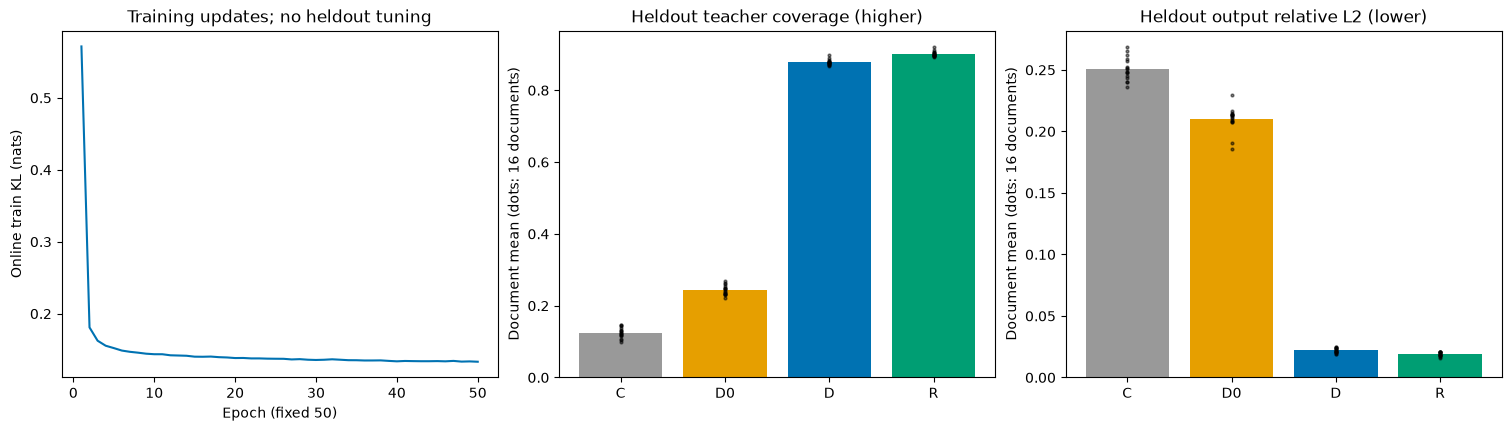

In [11]:
display(Markdown('### 留出 16 份资料\n\n' + report.table(summary, 'heldout')))
display(Markdown('### 训练 48 份资料：冻结参数重评\n\n' + report.table(summary, 'train')))
import matplotlib.pyplot as plt
fig = report.plot_overview(summary)
plt.show()

点代表完整资料，不能把同一资料的 4 条查询×8 个组当作 32 个独立样本。下面保留全部留出资料的配对变化。KL 和输出误差的负值表示改善；coverage 的正值表示改善。

**Δ 表示“训练后 D 减去训练前 D0”**；负的 ΔKL/Δ误差是改善，正的 Δcoverage 是改善。资料号 `G3a-T1-2K-48` 表示本阶段、单值查询、约 2K、资料序号 48，不是模型输出。预算字段 `selected_count` 是总读取数，`candidate_count` 是候选数 M，`legal` 是本步合法长度 N；列表的两端表示实际最小/最大值。

In [12]:
lines=['| 资料 | ΔKL (D−D0) | Δcoverage | Δ相对输出误差 |', '|---|---:|---:|---:|']
for row in summary['paired']:
    if row['split'] == 'heldout':
        lines.append(f"| {row['doc_id']} | {row['delta_kl']:+.5f} | {row['delta_coverage']:+.5f} | {row['delta_output_error']:+.5f} |")
display(Markdown('\n'.join(lines)))
print('实际读取预算范围:', summary['range'])
print('rho:', evidence['manifest']['config']['rho'])
print('k/M 范围:', min(r['k']/r['candidate_count'] for r in evidence['records']), max(r['k']/r['candidate_count'] for r in evidence['records']))
print('总读取比例范围:', min(r['selected_count']/r['legal'] for r in evidence['records']), max(r['selected_count']/r['legal'] for r in evidence['records']))

| 资料 | ΔKL (D−D0) | Δcoverage | Δ相对输出误差 |
|---|---:|---:|---:|
| G3a-T1-2K-48 | -2.72824 | +0.62241 | -0.19430 |
| G3a-T1-2K-49 | -2.74375 | +0.61418 | -0.16660 |
| G3a-T1-2K-50 | -2.62398 | +0.64105 | -0.19138 |
| G3a-T1-2K-51 | -2.62435 | +0.63910 | -0.18963 |
| G3a-T1-2K-52 | -2.79568 | +0.62136 | -0.18911 |
| G3a-T1-2K-53 | -2.72873 | +0.63455 | -0.18544 |
| G3a-T1-2K-54 | -2.68788 | +0.63890 | -0.18558 |
| G3a-T1-2K-55 | -2.66200 | +0.64109 | -0.18903 |
| G3a-T1-2K-56 | -2.91280 | +0.66628 | -0.21016 |
| G3a-T1-2K-57 | -2.77553 | +0.66076 | -0.19099 |
| G3a-T1-2K-58 | -2.70327 | +0.64266 | -0.19207 |
| G3a-T1-2K-59 | -2.68317 | +0.62965 | -0.19036 |
| G3a-T1-2K-60 | -2.74072 | +0.61783 | -0.19203 |
| G3a-T1-2K-61 | -2.74852 | +0.63411 | -0.19279 |
| G3a-T1-2K-62 | -2.67611 | +0.63492 | -0.18796 |
| G3a-T1-2K-63 | -2.72565 | +0.61668 | -0.16070 |

实际读取预算范围: {'k0': [249, 260], 'k': [249, 260], 'selected_count': [317, 328], 'candidate_count': [1935, 2049], 'legal': [2003, 2117]}
rho: 0.125
k/M 范围: 0.12684365781710916 0.12893243940175347
总读取比例范围: 0.15493623051487954 0.15844544095665172


## 5. 同一道题，训练前后选中了什么？

按预登记规则，展示留出最终查询在 8 组平均 coverage 上变化最大与最差的两份资料。极值用于理解差异，不是随机抽出的典型案例。图固定展示 KV 组 0，因此图中这一组的变化不必等于 8 组平均变化。

横轴是原始 token 位置，竖线是实际选中的条目，阴影标出被问记录。首部与近期固定集合也包含在名单中。

图中的 `Original token position (no renumbering)` 是保持原编号的位置；`Target record` 阴影包含整条目标记录的编号、值和标点。案例的“目标直接选中 token 数”数位置；与同表的教师权重 coverage 分母不同。代码 `group=0` 是第一组，正文“第14层”按 1 开始数，代码层下标为 13。

### 最大改善：G3a-T1-2K-57

问题：编号 1340 对应的数值是多少？只输出该编号对应的四位数值，不要输出编号。

目标记录：`编号 1340：1316`。8 组平均 coverage 变化：+0.67768。

| 方法（组0） | 条件coverage | 相对输出误差 | 目标记录直接选中token数 |
|---|---:|---:|---:|
| C | 0.11778 | 0.07435 | 3/11 |
| D0 | 0.36965 | 0.08774 | 8/11 |
| D | 0.79385 | 0.01493 | 4/11 |
| R | 0.81297 | 0.01379 | 4/11 |

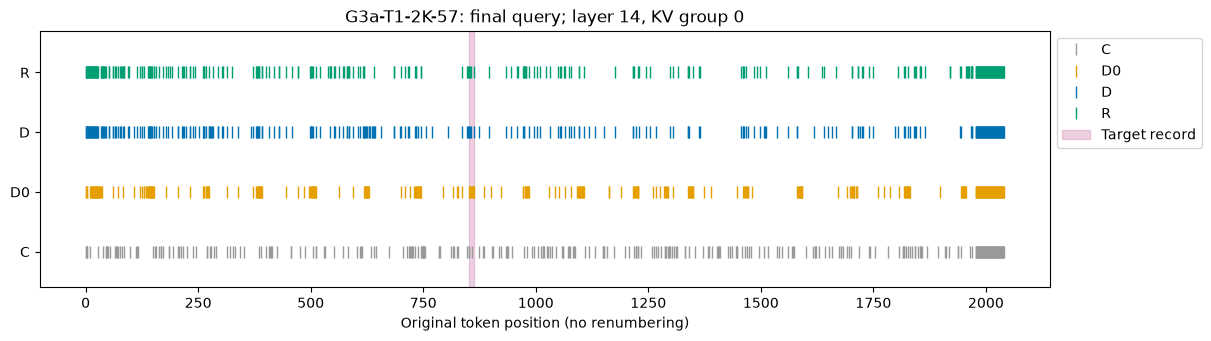

### 最差变化：G3a-T1-2K-48

问题：编号 5270 对应的数值是多少？只输出该编号对应的四位数值，不要输出编号。

目标记录：`编号 5270：6692`。8 组平均 coverage 变化：+0.62089。

| 方法（组0） | 条件coverage | 相对输出误差 | 目标记录直接选中token数 |
|---|---:|---:|---:|
| C | 0.15331 | 0.08645 | 2/11 |
| D0 | 0.35163 | 0.10702 | 9/11 |
| D | 0.77473 | 0.01880 | 5/11 |
| R | 0.79269 | 0.01742 | 7/11 |

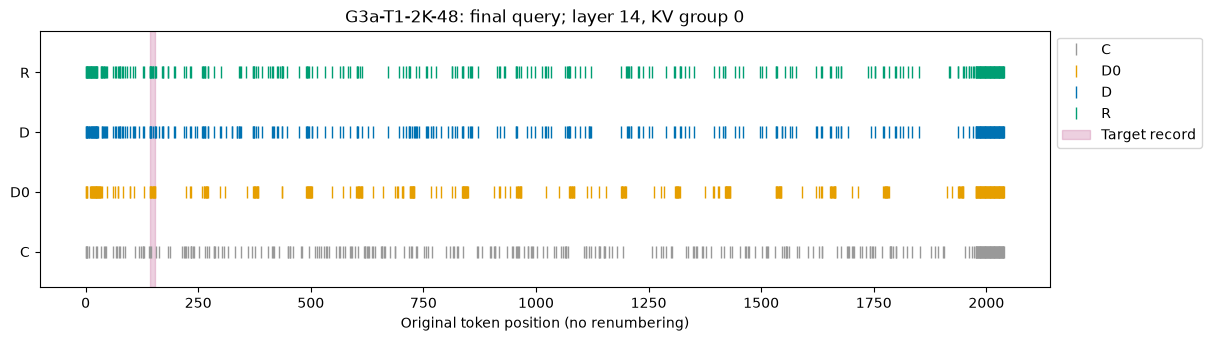

In [13]:
for case in summary['cases']:
    display(Markdown(f"### {case['label']}：{case['doc_id']}\n\n{case['question']}\n\n目标记录：`{'；'.join(case['target_records'])}`。8 组平均 coverage 变化：{case['delta_coverage']:+.5f}。"))
    lines=['| 方法（组0） | 条件coverage | 相对输出误差 | 目标记录直接选中token数 |', '|---|---:|---:|---:|']
    target={p for a,b in case['target_spans'] for p in range(a,b)}
    for row in case['records']:
        pos=set(row['positions'][0])
        lines.append(f"| {row['method']} | {row['coverage'][0]:.5f} | {row['output_relative_l2'][0]:.5f} | {len(pos & target)}/{len(target)} |")
    display(Markdown('\n'.join(lines)))
    fig=report.plot_case(case)
    plt.show()

### 平均改善之后，还剩什么？

本轮没有相对 D0 退化的留出查询/组，也没有生成新答案，不能编造“答题失败”。下面列出各组差异，以及现有记录里 D 的相对输出误差最大的一行。这个残余误差案例在运行后选出，只用于解释，未影响训练配置。

下面 `query` 是抽取的查询行序号，`group` 是 K/V 组序号，`relative_L2` 是刚定义的相对读出误差。**残余误差**表示训练后仍与参照不一致的部分，不表示某道题答错。

In [14]:
lines=['| KV组 | m_C | KL：D0→D | coverage：D0→D | 相对输出误差：D0→D |', '|---|---:|---:|---:|---:|']
for item in summary['heldout_by_group']:
    a,d=item['methods']['D0'],item['methods']['D']
    lines.append(f"| {item['group']} | {d['candidate_mass']:.4f} | {a['kl']:.4f} → {d['kl']:.4f} | {a['coverage']:.4f} → {d['coverage']:.4f} | {a['output_relative_l2']:.4f} → {d['output_relative_l2']:.4f} |")
display(Markdown('\n'.join(lines)))
res=summary['residual_case'];g=res['group']
print('残余误差案例:', res['doc_id'], 'query',res['query_index'],'group',g)
for row in res['records']:
    print(row['method'], 'coverage',round(row['coverage'][g],5),'relative_L2',round(row['output_relative_l2'][g],5))
held=summary['aggregate']['heldout']['D']
print('固定集合平均已有的完整权重:', round(1-held['candidate_mass'],5))
print('D 平均遗漏的完整权重:', round(held['missed_full_mass'],5))
print('不能以平均 m_C 乘平均 (1-coverage) 代替逐行计算。')

| KV组 | m_C | KL：D0→D | coverage：D0→D | 相对输出误差：D0→D |
|---|---:|---:|---:|---:|
| 0 | 0.1057 | 2.6658 → 0.0690 | 0.1566 → 0.8602 | 0.2575 → 0.0273 |
| 1 | 0.3152 | 2.9844 → 0.0478 | 0.5946 → 0.9330 | 0.1489 → 0.0373 |
| 2 | 0.3215 | 3.0747 → 0.0928 | 0.3308 → 0.9127 | 0.3022 → 0.0255 |
| 3 | 0.3284 | 2.8053 → 0.0284 | 0.2214 → 0.8835 | 0.2419 → 0.0377 |
| 4 | 0.1075 | 3.0651 → 0.1569 | 0.0734 → 0.9276 | 0.1352 → 0.0129 |
| 5 | 0.0364 | 2.3081 → 0.0952 | 0.0878 → 0.8264 | 0.0324 → 0.0089 |
| 6 | 0.0419 | 2.2634 → 0.5538 | 0.2121 → 0.7475 | 0.2197 → 0.0172 |
| 7 | 0.3998 | 3.6961 → 0.0389 | 0.2721 → 0.9355 | 0.3419 → 0.0089 |

残余误差案例: G3a-T1-2K-54 query 0 group 3
C coverage 0.07312 relative_L2 0.59528
D0 coverage 0.1846 relative_L2 0.47879
D coverage 0.84217 relative_L2 0.12779
R coverage 0.8481 relative_L2 0.12241
固定集合平均已有的完整权重: 0.79294
D 平均遗漏的完整权重: 0.01444
不能以平均 m_C 乘平均 (1-coverage) 代替逐行计算。


## 6. 哪条证据成立，哪条仍然没有？

训练损失下降、留出 KL 下降、选中更多教师权重、局部输出更接近完整读取，是四项不同观察。相同名额下，R 可以选到最多教师权重，但 V 的方向也会影响输出误差。

这些新资料仍使用同一生成器、提示和填充句库。留出改善可能说明学到了本分布中的稳定读取模式；不能自动解释成学会了找答案，更不能声称泛化到其他提示、长度、层或模型。

本轮没有稀疏自由生成、整模型任务分数、速度测量、全层训练或从资料阶段开始稀疏。完整代码、失败预检、参数和全部记录均保留；此处是当时的阶段边界；后来另行授权的各层训练与真实推理见第五、六课，不能把后来的成绩倒算进本课。

末格的 `.npz` 是保存数值数组的压缩文件：`index_initial` / `index_final` 分别存训练前/后索引参数，`features/` 保存冻结特征。`MPS` 是 PyTorch 调用 Apple GPU 的后端；“报告重建无 torch 依赖”仅指该报告脚本，不是说本课 CPU 算例也不用 PyTorch。

In [15]:
print('正式运行：', summary['run_id'])
print('运行源代码提交：', summary['run_commit'])
print('原始记录归档：', report.ARCHIVE.relative_to(ROOT))
print('初始/最终索引参数：', summary['run_id'] + '/index_initial.npz', summary['run_id'] + '/index_final.npz')
print('完整冻结特征：本机 runs/' + summary['run_id'] + '/features/；每份哈希在 manifest。')
print('精简报告重建：python scripts/g3a_report.py（无 torch 依赖）。')

正式运行： g3a-20261018T122927Z-formal
运行源代码提交： b998ee733b75af861613999fc3d4ec6c992b4835
原始记录归档： reports/provenance/g3a_evidence_20261018.tar.gz
初始/最终索引参数： g3a-20261018T122927Z-formal/index_initial.npz g3a-20261018T122927Z-formal/index_final.npz
完整冻结特征：本机 runs/g3a-20261018T122927Z-formal/features/；每份哈希在 manifest。
精简报告重建：python scripts/g3a_report.py（无 torch 依赖）。
